In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('heart.csv')

In [4]:
df.sample(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
137,62,1,1,128,208,1,0,140,0,0.0,2,0,2,1
54,63,0,2,135,252,0,0,172,0,0.0,2,0,2,1
276,58,1,0,146,218,0,1,105,0,2.0,1,1,3,0
33,54,1,2,125,273,0,0,152,0,0.5,0,1,2,1
199,65,1,0,110,248,0,0,158,0,0.6,2,2,1,0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11780\1993125383.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['age'])
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11780\1993125383.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['trestbps'])


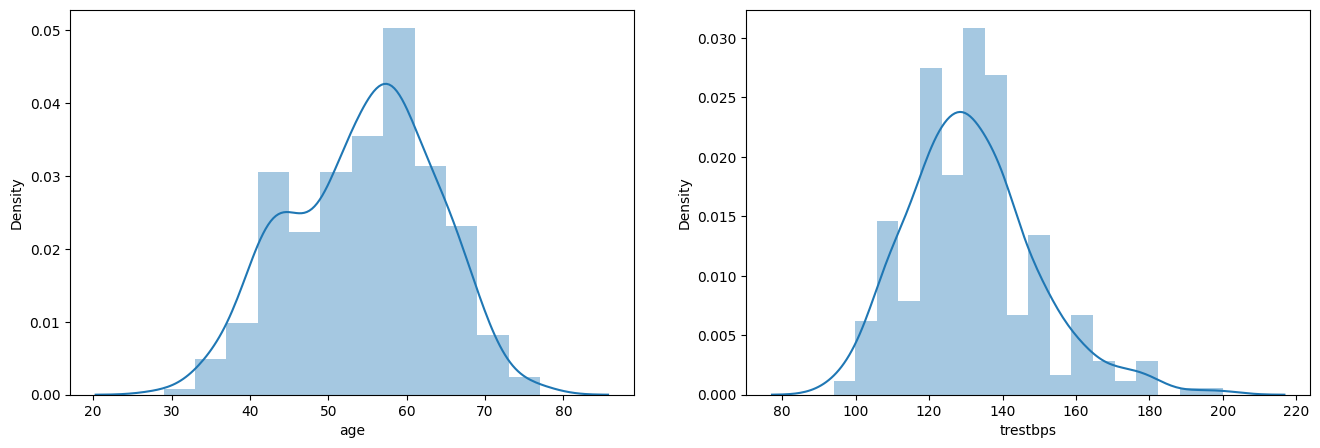

In [6]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['age'])
plt.subplot(1,2,2)
sns.distplot(df['trestbps'])
plt.show()

In [7]:
print('Mean of age',df['age'].mean())
print('std value of age',df['age'].std())
print('min value of trestbps',df['trestbps'].min())
print('max value of trestbps',df['trestbps'].max())

Mean of age 54.366336633663366
std value of age 9.082100989837858
min value of trestbps 94
max value of trestbps 200


In [13]:
#finding the boundry values
print('Highest allowed',df['trestbps'].mean()+3*df['trestbps'].std())
print('lowest allowed',df['trestbps'].mean()-3*df['trestbps'].std())

Highest allowed 184.23819081678892
lowest allowed 79.00933393568636


In [14]:
#finding outliers
df[(df['trestbps']>184.23)|(df['trestbps']<79.00)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
223,56,0,0,200,288,1,0,133,1,4.0,0,2,3,0
248,54,1,1,192,283,0,0,195,0,0.0,2,1,3,0


In [15]:
#trimming
new_df=df[(df['trestbps']<184.23)&(df['trestbps']>79.00)]

In [18]:
#Approch 2
df['trestbps_zscore']=(df['trestbps']-df['trestbps'].mean())/df['trestbps'].std()

In [19]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,trestbps_zscore
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1,0.762694
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1,-0.092585
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1,-0.092585
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1,-0.662770
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1,-0.662770


In [20]:
df[df['trestbps_zscore']>3]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,trestbps_zscore
223,56,0,0,200,288,1,0,133,1,4.0,0,2,3,0,3.898716
248,54,1,1,192,283,0,0,195,0,0.0,2,1,3,0,3.442567


In [21]:
df[df['trestbps_zscore']<-3]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,trestbps_zscore


In [23]:
new_df=df[(df['trestbps_zscore']<3) & (df['trestbps_zscore']>-3)]

In [24]:
new_df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,trestbps_zscore
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1,0.762694
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1,-0.092585
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1,-0.092585
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1,-0.662770
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1,-0.662770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0,0.477601
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0,-1.232956
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0,0.705675
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0,-0.092585


In [25]:
#capping 
upper_limit=df['trestbps'].mean()+3*df['trestbps'].std()
lower_limit=df['trestbps'].mean()-3*df['trestbps'].std()

In [28]:
df['trestbps']=np.where(
    df['trestbps']>upper_limit,
    upper_limit,
    np.where(
        df['trestbps']<lower_limit,
        lower_limit,
        df['trestbps']
    )
)

In [29]:
np.where(x,y,z)

NameError: name 'x' is not defined